In [1]:
import os
import sys
import pandas as pd
import numpy as np
import yaml

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))
from evaluation import plot_calibration_curve, decision_curve_analysis, plot_decision_curve
from plotting_utils import save_fig

with open(os.path.join(PROJECT_ROOT, "config", "config.yaml")) as f:
    config = yaml.safe_load(f)

PROCESSED_DIR = os.path.join(PROJECT_ROOT, config["paths"]["processed_dir"])
TABLES_DIR = os.path.join(PROJECT_ROOT, config["paths"]["tables_dir"])

In [2]:
def run_calibration_dca(dataset_tag, data_dir):
    test_pred = pd.read_csv(os.path.join(data_dir, "base_predictions_test.csv"))
    y_test = test_pred["y_true"].values
    proba_test = test_pred["rf"].values  # the proposed model, fixed as RF across all datasets

    print(f"\n{'='*50}\n{dataset_tag}\n{'='*50}")
    print(f"n = {len(y_test)}, prevalence = {y_test.mean():.4f}")

    mean_pred, frac_pos = plot_calibration_curve(y_test, proba_test, PROJECT_ROOT, dataset_tag,
                                                   n_bins=10, save_fig_fn=save_fig)

    dca_df = decision_curve_analysis(y_test, proba_test)
    plot_decision_curve(dca_df, PROJECT_ROOT, dataset_tag, save_fig_fn=save_fig)

    dca_df.to_csv(os.path.join(TABLES_DIR, f"{dataset_tag}_decision_curve.csv"), index=False)

    # Quick summary: range of thresholds where the model beats BOTH reference strategies
    beats_both = dca_df[(dca_df["net_benefit_model"] > dca_df["net_benefit_treat_all"]) &
                         (dca_df["net_benefit_model"] > dca_df["net_benefit_treat_none"])]
    if len(beats_both) > 0:
        print(f"Model exceeds both 'treat all' and 'treat none' for thresholds "
              f"{beats_both['threshold'].min():.2f}–{beats_both['threshold'].max():.2f}")
    else:
        print("Model does not clearly exceed both reference strategies at any tested threshold.")

    return dca_df


pakistan
n = 2798, prevalence = 0.6372
Saved figure: C:\maternal-mental-health-risk\reports\figures\pakistan\pakistan_calibration_curve.png


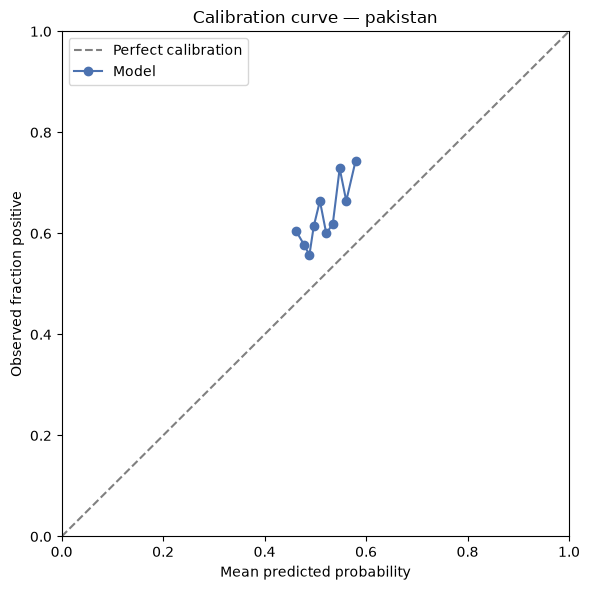

Saved figure: C:\maternal-mental-health-risk\reports\figures\pakistan\pakistan_decision_curve.png


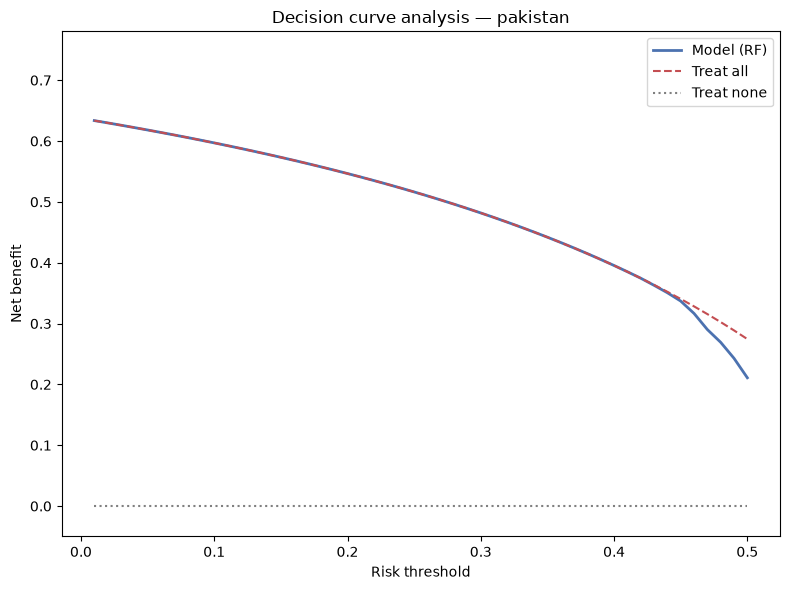

Model exceeds both 'treat all' and 'treat none' for thresholds 0.16–0.41


In [3]:
dca_pk = run_calibration_dca("pakistan", os.path.join(PROCESSED_DIR, "pakistan"))


arab5_depression
n = 301, prevalence = 0.4385
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_depression\arab5_depression_calibration_curve.png


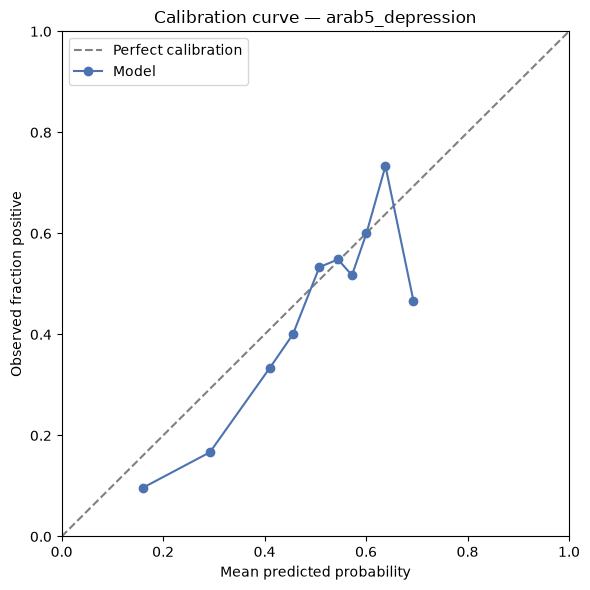

Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_depression\arab5_depression_decision_curve.png


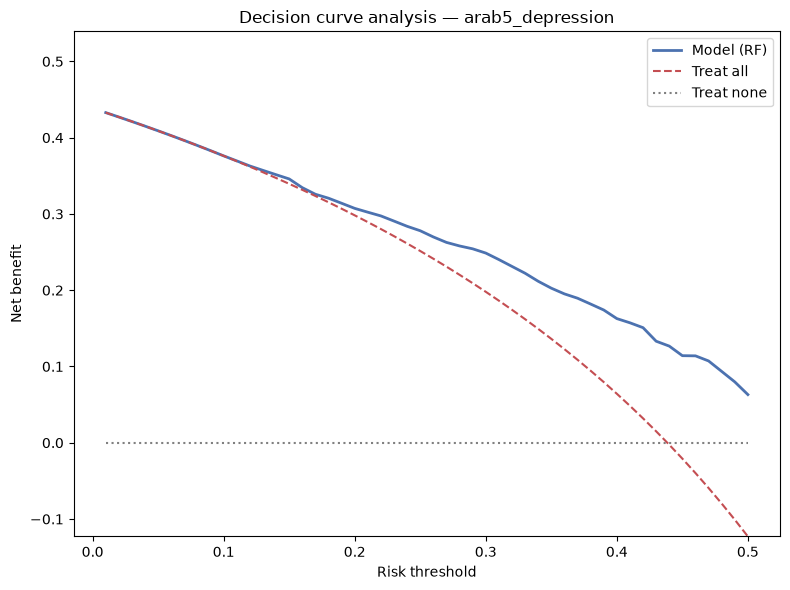

Model exceeds both 'treat all' and 'treat none' for thresholds 0.11–0.50


In [4]:
dca_ar_dep = run_calibration_dca("arab5_depression", os.path.join(PROCESSED_DIR, "arab5_depression"))


arab5_anxiety
n = 191, prevalence = 0.7225
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_anxiety\arab5_anxiety_calibration_curve.png


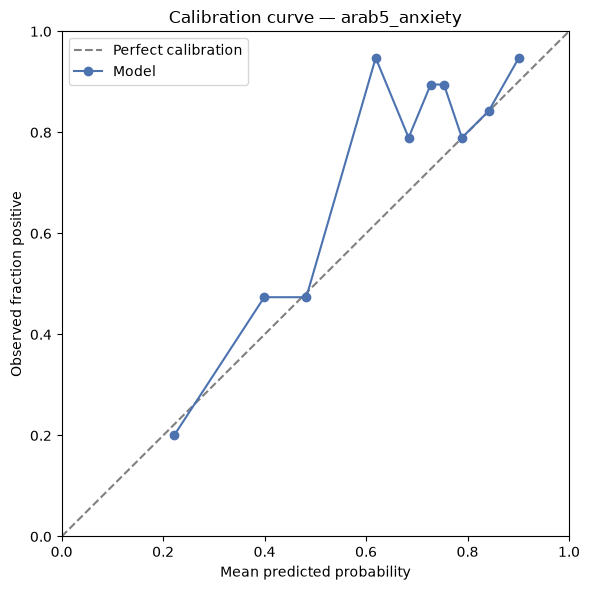

Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5_anxiety\arab5_anxiety_decision_curve.png


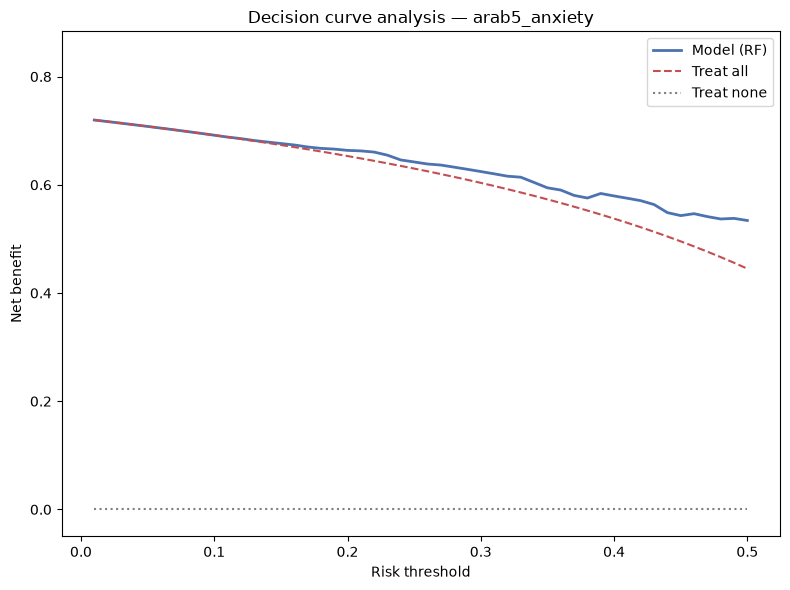

Model exceeds both 'treat all' and 'treat none' for thresholds 0.12–0.50


In [5]:
dca_ar_anx = run_calibration_dca("arab5_anxiety", os.path.join(PROCESSED_DIR, "arab5_anxiety"))


uganda
n = 2841, prevalence = 0.4808
Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\uganda_calibration_curve.png


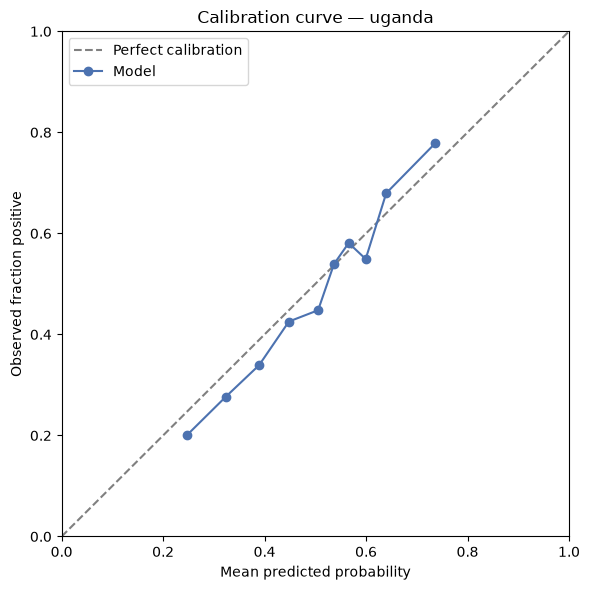

Saved figure: C:\maternal-mental-health-risk\reports\figures\uganda\uganda_decision_curve.png


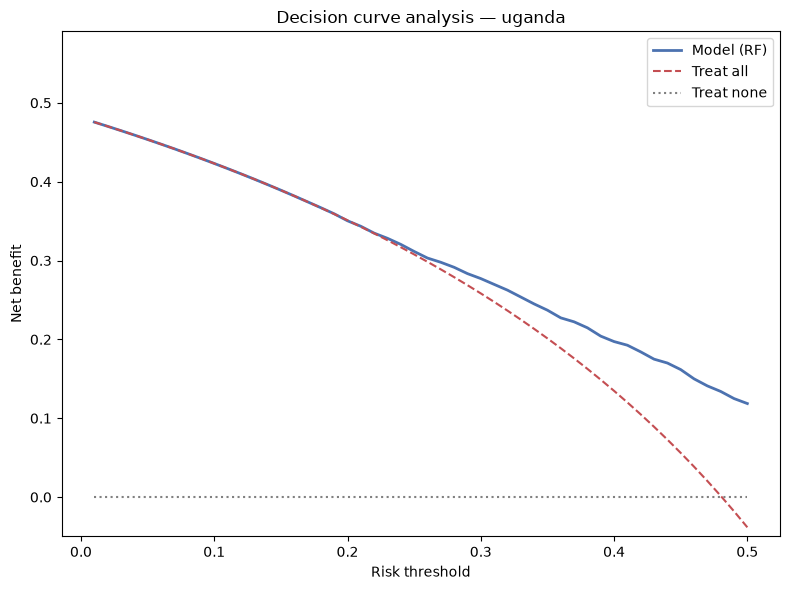

Model exceeds both 'treat all' and 'treat none' for thresholds 0.18–0.50


In [6]:
dca_ug = run_calibration_dca("uganda", os.path.join(PROCESSED_DIR, "uganda"))